# 03 — BiLSTM sentiment model

Train a binary sentiment classifier from the arrays saved by notebook 02. The model is: token IDs → trainable embedding → bidirectional LSTM → sigmoid output. Labels are `0` for negative and `1` for positive.

Run the **Save the prepared data** cell in notebook 02 first. This notebook fits on training data, uses validation data for early stopping, and evaluates the test set only after training is finished.

## Environment

Use the same Python 3.11 environment and kernel for notebooks 01, 02, and 03. TensorFlow cannot be installed in the existing Python 3.15 `.venv`. Set up the shared environment with the single `requirements.txt`:

```bash
python3.11 -m venv .venv-bilstm
.venv-bilstm/bin/python -m pip install -r requirements.txt
.venv-bilstm/bin/python -m ipykernel install --user --name scm-sentiment-analysis --display-name "Python (scm-sentiment-analysis)"
```

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
PREPARED_DIR = Path("data/prepared")
MODEL_DIR = Path("models")

## 1. Load the prepared splits

In [3]:
required = [PREPARED_DIR / f"{kind}_{name}.npy" for name in ("train", "validation", "test") for kind in ("X", "y")]
required += [PREPARED_DIR / "vocab.json", PREPARED_DIR / "metadata.json"]
missing = [str(path) for path in required if not path.exists()]
if missing:
    raise FileNotFoundError(f"Run notebook 02's save cell first. Missing: {missing}")

X = {name: np.load(PREPARED_DIR / f"X_{name}.npy") for name in ("train", "validation", "test")}
y = {name: np.load(PREPARED_DIR / f"y_{name}.npy") for name in X}
with (PREPARED_DIR / "metadata.json").open(encoding="utf-8") as file:
    metadata = json.load(file)
with (PREPARED_DIR / "vocab.json").open(encoding="utf-8") as file:
    vocab = json.load(file)
MAX_LENGTH = metadata["max_length"]
VOCAB_SIZE = metadata["vocab_size"]
assert len(vocab) == VOCAB_SIZE and vocab["<pad>"] == 0 and vocab["<unk>"] == 1
for name in X:
    assert X[name].ndim == 2 and X[name].shape[1] == MAX_LENGTH
    assert len(X[name]) == len(y[name])
    assert X[name].min() >= 0 and X[name].max() < VOCAB_SIZE
    assert set(np.unique(y[name])).issubset({0, 1})
    print(f"{name}: {len(y[name]):,} rows, positive rate {y[name].mean() * 100:.2f}%")
print(f"Vocabulary: {VOCAB_SIZE:,}; sequence length: {MAX_LENGTH}")

train: 1,233,032 rows, positive rate 49.76%
validation: 154,128 rows, positive rate 49.76%
test: 154,131 rows, positive rate 49.76%
Vocabulary: 40,000; sequence length: 31


## 2. Define the model

The embedding learns word vectors from the training data. Padding ID `0` is masked so padded positions do not contribute to the BiLSTM state. The sigmoid output estimates the probability of the positive class.

In [4]:
EMBEDDING_DIM = 128
LSTM_UNITS = 64
BATCH_SIZE = 256
EPOCHS = 5

inputs = tf.keras.Input(shape=(MAX_LENGTH,), dtype="int32", name="token_ids")
features = tf.keras.layers.Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True)(inputs)
features = tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(LSTM_UNITS))(features)
features = tf.keras.layers.Dropout(0.3)(features)
outputs = tf.keras.layers.Dense(1, activation="sigmoid", name="positive_probability")(features)
model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.BinaryAccuracy(name="accuracy"), tf.keras.metrics.AUC(name="auc")],
)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ token_ids           │ (None, 31)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 31, 128)   │  5,120,000 │ token_ids[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 31)        │          0 │ token_ids[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 128)       │     98,816 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positive_probabili… │ (None, 1)         │        129 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,218,945 (19.91 MB)

 Trainable params: 5,218,945 (19.91 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Train and select the best epoch

The full training split has about 1.23 million tweets, so training can take a while on a CPU. Early stopping restores the weights from the best validation-loss epoch. The best model is saved in `models/`.

In [5]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
best_model_path = MODEL_DIR / "bilstm_sentiment.keras"
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint(best_model_path, monitor="val_loss", save_best_only=True),
]
history = model.fit(
    X["train"], y["train"],
    validation_data=(X["validation"], y["validation"]),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1,
)
print(f"Best model saved to {best_model_path}")

Epoch 1/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 434s 90ms/step - accuracy: 0.8156 - auc: 0.8971 - loss: 0.4049 - val_accuracy: 0.8323 - val_auc: 0.9140 - val_loss: 0.3728
Epoch 2/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 421s 87ms/step - accuracy: 0.8459 - auc: 0.9247 - loss: 0.3492 - val_accuracy: 0.8352 - val_auc: 0.9167 - val_loss: 0.3695
Epoch 3/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 428s 89ms/step - accuracy: 0.8656 - auc: 0.9405 - loss: 0.3114 - val_accuracy: 0.8317 - val_auc: 0.9108 - val_loss: 0.3916
Epoch 4/5
4817/4817 ━━━━━━━━━━━━━━━━━━━━ 417s 86ms/step - accuracy: 0.8858 - auc: 0.9555 - loss: 0.2700 - val_accuracy: 0.8261 - val_auc: 0.9001 - val_loss: 0.4464
Best model saved to models/bilstm_sentiment.keras


## 4. Inspect training and validation results

Use the validation curves to spot overfitting or an unstable training run before looking at the test set.

,accuracy,auc,loss,val_accuracy,val_auc,val_loss
0,0.8156,0.8971,0.4049,0.8323,0.9140,0.3728
1,0.8459,0.9247,0.3492,0.8352,0.9167,0.3695
2,0.8656,0.9405,0.3114,0.8317,0.9108,0.3916
3,0.8858,0.9555,0.2700,0.8261,0.9001,0.4464


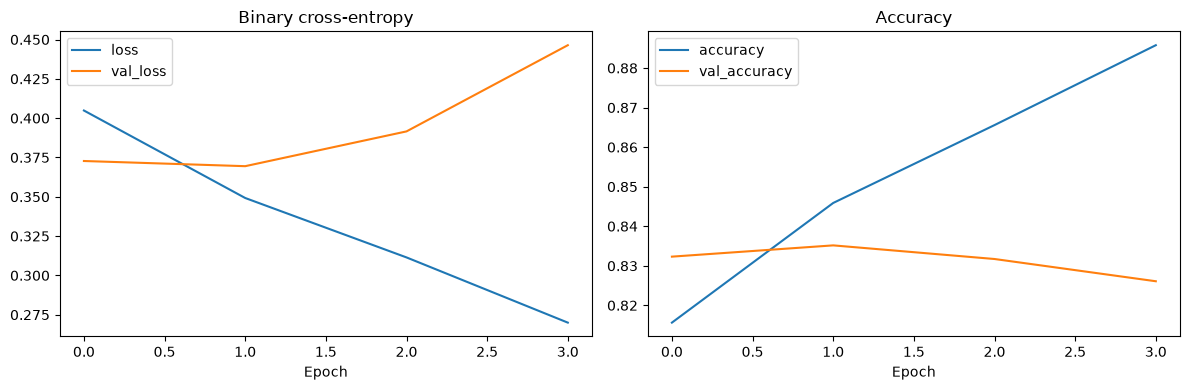

In [6]:
history_df = pd.DataFrame(history.history)
display(history_df.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
history_df[["loss", "val_loss"]].plot(ax=axes[0], title="Binary cross-entropy")
history_df[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Accuracy")
for ax in axes:
    ax.set_xlabel("Epoch")
plt.tight_layout()
plt.show()

## 5. Final test evaluation

Run this once after model choices are settled. The confusion table counts true labels by row and predicted labels by column.

In [7]:
best_model = tf.keras.models.load_model(best_model_path)
test_metrics = best_model.evaluate(X["test"], y["test"], batch_size=BATCH_SIZE, return_dict=True)
display(pd.Series(test_metrics, name="test").round(4).to_frame())
positive_probability = best_model.predict(X["test"], batch_size=BATCH_SIZE, verbose=1).ravel()
predicted = (positive_probability >= 0.5).astype(np.int8)
confusion = pd.crosstab(
    pd.Series(y["test"], name="Actual").map({0: "negative", 1: "positive"}),
    pd.Series(predicted, name="Predicted").map({0: "negative", 1: "positive"}),
    dropna=False,
).reindex(index=["negative", "positive"], columns=["negative", "positive"], fill_value=0)
display(confusion)
precision = confusion.loc["positive", "positive"] / max(1, confusion["positive"].sum())
recall = confusion.loc["positive", "positive"] / max(1, confusion.loc["positive"].sum())
f1 = 2 * precision * recall / max(1e-12, precision + recall)
print(f"Positive-class precision: {precision:.3f}; recall: {recall:.3f}; F1: {f1:.3f}")

603/603 ━━━━━━━━━━━━━━━━━━━━ 14s 23ms/step - accuracy: 0.8348 - auc: 0.9157 - loss: 0.3717


,test
accuracy,0.8348
auc,0.9157
loss,0.3717


603/603 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step


Predicted,negative,positive
Actual,,
negative,62949,14479
positive,10983,65720


Positive-class precision: 0.819; recall: 0.857; F1: 0.838
